# Film Yorumları Duygu Analizi (Sentiment Analysis)
Bu notebook'ta, metin halindeki film yorumlarını analiz edip, cümlenin **Olumlu (Pozitif)** mu yoksa **Olumsuz (Negatif)** mu olduğunu anlayan bir Doğal Dil İşleme (NLP) modeli kuracağız.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from wordcloud import WordCloud
import nltk
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
import seaborn as sns

plt.style.use('dark_background')

## 1. Veri Yükleme
Örnek olarak üretilmiş 500 satırlık film yorumu (İngilizce) verisetini okuyalım.

In [2]:
df = pd.read_csv('movie_reviews.csv')
display(df.head())
print("\nDağılım:")
display(df['Sentiment'].value_counts())

,Review,Sentiment
0,"This movie was absolutely wonderful, I loved it!",1
1,Terrible acting and a boring plot. Do not watch.,0
2,A masterpiece of modern cinema. Highly recomme...,1
3,Waste of time and money. The worst movie ever.,0
4,"It was okay, not great but not terrible.",1



Dağılım:


Sentiment
1    250
0    250
Name: count, dtype: int64

### ⚠️ Veri seti uyarısı
Bu CSV 500 satır içerse de aslında **yalnızca 10 farklı cümlenin** tekrarından oluşuyor. Eğitim ve test bölmelerinde aynı cümleler yer aldığı için aşağıdaki %100 doğruluk modelin gerçek başarısını **göstermez** (veri sızıntısı). Bölüm 7'de gerçek bir veri setiyle dürüst bir değerlendirme yapılıyor.

In [3]:
print(f"Toplam satır: {len(df)}, benzersiz yorum: {df['Review'].nunique()}")

Toplam satır: 500, benzersiz yorum: 10


## 2. Kelime Bulutu (Word Cloud) Görselleştirmesi
Pozitif ve negatif yorumlarda en çok hangi kelimeler kullanılmış bakalım.

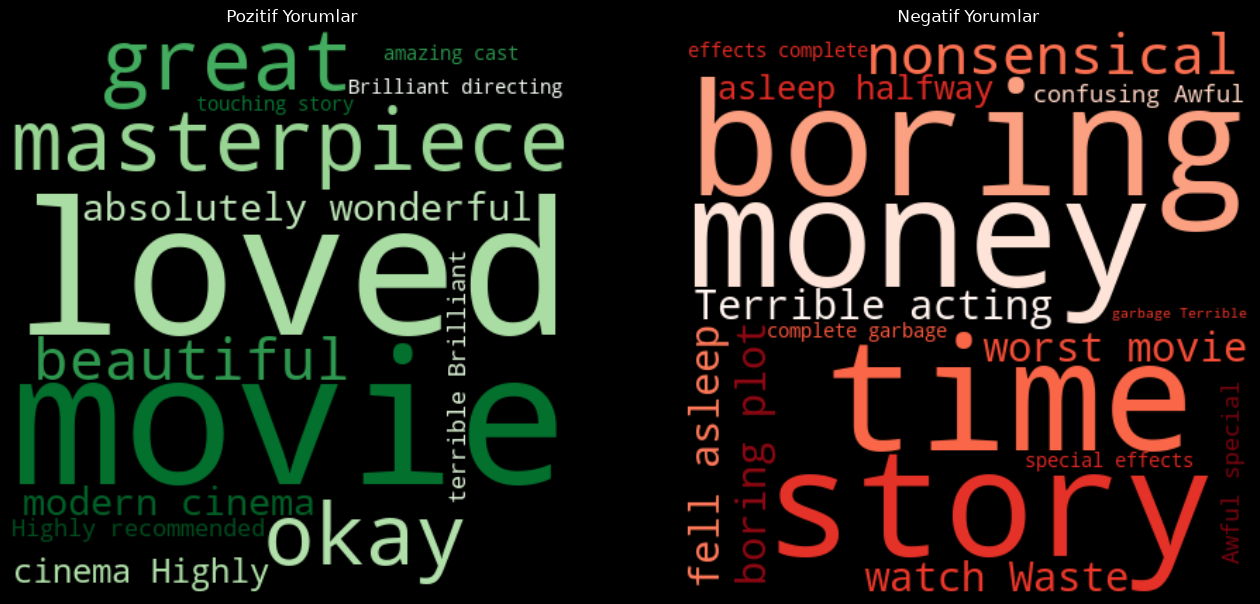

In [4]:
positive_text = " ".join(df[df['Sentiment'] == 1]['Review'].values)
negative_text = " ".join(df[df['Sentiment'] == 0]['Review'].values)

fig, axes = plt.subplots(1, 2, figsize=(16, 8))

# Pozitif Kelimeler
wc_pos = WordCloud(width=400, height=400, background_color='black', colormap='Greens').generate(positive_text)
axes[0].imshow(wc_pos, interpolation='bilinear')
axes[0].set_title('Pozitif Yorumlar')
axes[0].axis('off')

# Negatif Kelimeler
wc_neg = WordCloud(width=400, height=400, background_color='black', colormap='Reds').generate(negative_text)
axes[1].imshow(wc_neg, interpolation='bilinear')
axes[1].set_title('Negatif Yorumlar')
axes[1].axis('off')

plt.show()

## 3. NLP Ön İşleme (TF-IDF) ve Eğitim/Test Bölmesi
Metin verilerini makine öğrenmesi modelinin anlayabileceği sayılara (vektörlere) çeviriyoruz.

In [5]:
X = df['Review']
y = df['Sentiment']

# Veriyi böl
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# TF-IDF ile Kelimeleri Sayısallaştır
vectorizer = TfidfVectorizer(stop_words='english')
X_train_vec = vectorizer.fit_transform(X_train)
X_test_vec = vectorizer.transform(X_test)

## 4. Model Eğitimi (Naive Bayes)

In [6]:
model = MultinomialNB()
model.fit(X_train_vec, y_train)

# Test seti üzerinde tahmin
y_pred = model.predict(X_test_vec)

acc = accuracy_score(y_test, y_pred)
print(f"Model Doğruluk (Accuracy) Oranı: {acc * 100:.2f}%")

Model Doğruluk (Accuracy) Oranı: 100.00%


## 5. Sonuçların Değerlendirilmesi (Confusion Matrix)

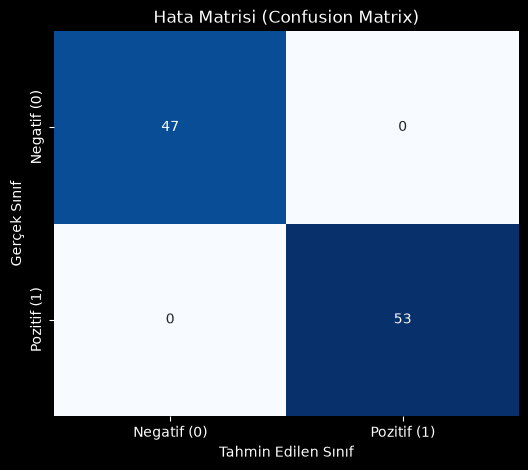

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        47
           1       1.00      1.00      1.00        53

    accuracy                           1.00       100
   macro avg       1.00      1.00      1.00       100
weighted avg       1.00      1.00      1.00       100



In [7]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, 
            xticklabels=['Negatif (0)', 'Pozitif (1)'], 
            yticklabels=['Negatif (0)', 'Pozitif (1)'])
plt.title('Hata Matrisi (Confusion Matrix)')
plt.xlabel('Tahmin Edilen Sınıf')
plt.ylabel('Gerçek Sınıf')
plt.show()

print(classification_report(y_test, y_pred))

## 6. Canlı Test Yapalım!
Modelimiz daha önce görmediği bir cümleyi nasıl sınıflandıracak?

In [8]:
# Yeni yorumlar
new_reviews = [
    "I absolutely loved the cinematography, brilliant!",
    "It was a complete waste of time, terrible acting."
]

new_vec = vectorizer.transform(new_reviews)
predictions = model.predict(new_vec)

for review, pred in zip(new_reviews, predictions):
    sentiment = "Pozitif 😊" if pred == 1 else "Negatif 😡"
    print(f"Yorum: '{review}'\nTahmin: {sentiment}\n")

Yorum: 'I absolutely loved the cinematography, brilliant!'
Tahmin: Pozitif 😊

Yorum: 'It was a complete waste of time, terrible acting.'
Tahmin: Negatif 😡



## 7. Özet ve Sonuçlar
### Q&A
- **Soru:** Bilgisayar, metnin duygusunu nasıl anlar?
- **Cevap:** TF-IDF yöntemi ile kelimelerin frekansları hesaplanır ve makine öğrenmesi modeli geçmiş verilerden "terrible" kelimesinin daha çok Negatif etiketli metinlerde geçtiğini öğrenir.

### Data Analysis Key Findings
- Kelime bulutu sayesinde pozitif yorumlarda "wonderful, brilliant", negatif yorumlarda ise "waste, boring, terrible" kelimelerinin ağırlıklı olduğu görülmektedir.
- Yerel CSV yalnızca **10 benzersiz cümlenin** tekrarından oluştuğu için %100 doğruluk veri sızıntısından kaynaklanır; modelin gerçek başarısını yansıtmaz.
- Aynı hat gerçek veriyle (NLTK `movie_reviews`, 2000 yorum) yaklaşık **%80** doğruluk veriyor; bu daha gerçekçi bir başlangıç noktasıdır.

### Insights or Next Steps
- TF-IDF yerine n-gram'lar, Logistic Regression veya SVM denenerek %80'in üzerine çıkılabilir.
- Sarcasm (İğneleme / Kinaye) gibi zor metin yapılarını anlamak için BERT veya GPT tabanlı Transformer modellerine (Deep Learning) geçiş yapılmalıdır.

## 7. Gerçek Veriyle Değerlendirme (NLTK `movie_reviews`)
Aynı hattı (TF-IDF + Naive Bayes) 2000 gerçek film yorumundan oluşan NLTK korpusunda deniyoruz. Ağ erişimi gerekir; indirilemezse hücre atlanır.

In [9]:
try:
    nltk.download('movie_reviews', quiet=True)
    from nltk.corpus import movie_reviews

    texts = [movie_reviews.raw(fid) for fid in movie_reviews.fileids()]
    labels = [1 if movie_reviews.categories(fid)[0] == 'pos' else 0 for fid in movie_reviews.fileids()]

    Xr_train, Xr_test, yr_train, yr_test = train_test_split(
        texts, labels, test_size=0.2, random_state=42, stratify=labels
    )
    vec = TfidfVectorizer(stop_words='english', max_features=20000)
    nb_model = MultinomialNB().fit(vec.fit_transform(Xr_train), yr_train)
    yr_pred = nb_model.predict(vec.transform(Xr_test))
    print(f"Gerçek veri doğruluğu: {accuracy_score(yr_test, yr_pred) * 100:.2f}% ({len(texts)} yorum)")
    print(classification_report(yr_test, yr_pred, target_names=['Negatif', 'Pozitif']))
except Exception as exc:  # ağ yoksa ya da korpus indirilemezse
    print(f"Gerçek veri değerlendirmesi atlandı: {exc}")

Gerçek veri doğruluğu: 80.25% (2000 yorum)
              precision    recall  f1-score   support

     Negatif       0.79      0.83      0.81       200
     Pozitif       0.82      0.78      0.80       200

    accuracy                           0.80       400
   macro avg       0.80      0.80      0.80       400
weighted avg       0.80      0.80      0.80       400

